# TrustFin-SLM · Phase-4B.1 — Evidence-Grounded Verifier-Aware Risk Improvement

**Research objective:** Determine whether lightweight, inference-available financial grounding and program-verification features improve the **ranking of erroneous but executable financial programs**, compared with the frozen likelihood-only (B1) and original grounding-aware (B4) methods.

**Inputs:** Frozen E5 Qwen3-1.7B predictions and Phase-4A/4B research exports. **Training:** a small risk estimator only; **no SLM fine-tuning**. **Outputs:** I1–I9 analyses, fit-only model selection, optional secondary holdout evaluation, and a reproducible candidate method handoff to Phase-4C/test.

> **Crucial distinction:** This notebook is a *follow-up development experiment*. The previous Phase-4B/C holdout (185 FinQA examples) has already been inspected. **It must not be represented as a newly untouched holdout.** Select risk features, hyperparameters, coverage policy, and model using only 698 `calibration_fit` examples. Freeze decisions **before** any secondary holdout comparison. Only a separately protected FinQA test, evaluated once after final methodology freeze, can support a final generalization claim.

## Why is Phase-4B.1 necessary?

The frozen QLoRA E5 model achieved **37.60% correct written FinQA answers** and **67.50% correct executed FinQA program results** on 883 validation examples. Of 880 executable programs, **284 still executed to incorrect answers**. A syntax check cannot identify such semantically incorrect programs. Existing likelihood confidence showed weak error discrimination (fit ROC-AUC ≈ 0.585), and the original Phase-4B/C fit-only selection chose **B1 raw likelihood**, not B4 grounding-aware. Grounding-aware methods improved some calibration metrics but did **not** establish selective-risk superiority.

Therefore, this notebook investigates **testable financial evidence features** (literal provenance and question-local relevance), operation/structure signals, truncation, and calibrated risk estimation. Evidence features indicate *risk*, not verified semantic correctness. No gold values, correctness labels, model-selection folds, or example IDs can enter predictors.

### Experiments

| ID | What is tested | Meaning |
|---|---|---|
| I1 | Operand numerical provenance | Find missing/multiple-source/weakly supported operands |
| I2 | Question–evidence relevance | Test question-local lexical matching, not gold relevance |
| I3 | Program-operation consistency proxies | Structural/operation cues; true semantic check requires original question/context |
| I4 | Truncation-aware uncertainty | Compare context-length and truncation predictors |
| I5 | Simple verifier-aware risk models | Nested fit-only CV, low-capacity logistic estimators |
| I6 | Probability calibration | Cross-fitted sigmoid calibration vs uncalibrated estimates |
| I7 | Selective answering | Risk versus coverage, especially matched 80% coverage |
| I8 | Feature-group ablation | Isolate provenance/relevance/operation/truncation effects |
| I9 | Paired statistical checks + decision | Bootstrap uncertainty and a *fit-only* candidate freeze |

**Limits:** No LLM-derived semantic labels; no FinTrust test; no claims of causality or calibrated reliability until properly evaluated on unseen data.

## How to run — students' checklist

1. Use Python 3.10+ with `numpy`, `pandas`, `scikit-learn`, `scipy`, `matplotlib`, `joblib`, `nbformat` installed. **CPU is sufficient**. Optional installation cell below.
2. Keep these files alongside this notebook (or set their paths in the configuration cell):
   - **Required:** `Phase4A_Review_Package(1).zip` (Phase-4A; contains 883 FinQA features, separate labels and operand provenance cases).
   - **Required:** `Phase4B_Review_Package.zip` (prior Phase-4B baselines, fit-only freeze, B1/B4 secondary holdout scores).
   - **Optional:** `Phase3_TrustFin_Deliverable.zip` (predicted FinQA program strings for additional operation analysis).
   - **Optional:** original `artifacts/phase2_1/datasets/validation.jsonl` (question text; enables a *question–operation heuristic pilot*). The notebook never reads the protected test data.
3. Set `RUN_MODE = 'smoke'` first and run **Kernel → Restart & Run All**. Confirm all smoke checks pass. The smoke report is **not** an experiment result.
4. Change to `RUN_MODE = 'full'`, restart kernel, run all cells. Fit-only nested CV and candidate freeze occur **before** secondary holdout reports.
5. Review `artifacts/phase4b_1/manifests/phase4b1_readiness.json` and `phase4b1_fit_only_freeze.json`. An output `PASS` verifies pipeline integrity, **not superiority**. The report may explicitly state `NO_IMPROVEMENT`.
6. Upload the executed notebook and generated `Phase4B_1_Review_Package.zip` for research review. Do **not** tune again based on secondary holdout results.
7. If the optional original validation JSONL is not present, operation–question semantic heuristics are marked **PENDING**; the core I1–I9 run still completes.

Run all code cells from top to bottom. Keep the seeds, coverage choices, and the predeclared feature groups unchanged for the documented experiment.

In [1]:
# Optional dependency installation (turn on only if needed, then restart the kernel).
INSTALL_DEPS = False
if INSTALL_DEPS:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install',
                           'numpy>=1.24', 'pandas>=2', 'scikit-learn>=1.3',
                           'scipy>=1.10', 'matplotlib>=3.7', 'joblib>=1.3'])
    print('Restart the kernel, then run cells from the beginning.')
else:
    print('Using already installed Python packages.')

Using already installed Python packages.


In [2]:
from __future__ import annotations
import ast, os, re, json, hashlib, zipfile, time, math, sys, platform, warnings, io, copy
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.special import expit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
print('Python:',platform.python_version(), '| sklearn:',__import__('sklearn').__version__)

Python: 3.12.3 | sklearn: 1.9.1


## 0. Configuration and source isolation

Configuration supports both uploaded ZIP names and explicit user paths. All outputs are written to a **new** `phase4b_1` directory; no older experiment result or checkpoint is overwritten.

In [3]:
RUN_MODE = os.environ.get('TRUSTFIN_B1_MODE', 'smoke').lower()  # 'smoke' or 'full'
SEARCH_ROOT = Path(os.environ.get('TRUSTFIN_INPUT_DIR', str(Path.cwd()))).expanduser()
PHASE4A_ZIP = os.environ.get('TRUSTFIN_PHASE4A_ZIP', '')
PHASE4B_ZIP = os.environ.get('TRUSTFIN_PHASE4B_ZIP', '')
PHASE3_ZIP = os.environ.get('TRUSTFIN_PHASE3_ZIP', '')
PHASE2_VALIDATION_JSONL = os.environ.get('TRUSTFIN_PHASE2_VALIDATION_JSONL', '')
OUTPUT_ROOT = Path(os.environ.get('TRUSTFIN_PHASE4B1_OUTPUT', str(SEARCH_ROOT / 'artifacts' / 'phase4b_1')))

# Selection is fit-only. Holdout evaluation is secondary, after saving the freeze.
SECONDARY_HOLDOUT_REPORT = RUN_MODE == 'full'
TARGET_COVERAGE = 0.80
RISK_COVERAGES = [0.5, 0.7, 0.8, 0.9, 1.0]
N_OUTER = 5 if RUN_MODE == 'full' else 3
N_INNER = 3 if RUN_MODE == 'full' else 2
N_BOOT = 1200 if RUN_MODE == 'full' else 150
C_GRID = [0.1, 1.0]  # small pre-declared grid; no holdout tuning

assert RUN_MODE in {'smoke', 'full'}
for sub in ['manifests','tables','predictions','models','plots','analysis']:
    (OUTPUT_ROOT/sub).mkdir(parents=True, exist_ok=True)


def find_input(filename, supplied):
    if supplied:
        path = Path(supplied).expanduser()
        if not path.is_file(): raise FileNotFoundError(path)
        return path.resolve()

    # Prefer canonical repository artifacts over duplicate notebook-local copies.
    bases = [SEARCH_ROOT, Path.cwd(), *Path.cwd().parents, Path('/mnt/data')]
    repo_roots = [base for base in bases
                  if (base/'artifacts/phase4a').is_dir()
                  and (base/'artifacts/phase4b_full').is_dir()]
    roots = []
    for base in repo_roots + bases:
        for relative in ['artifacts/phase4a', 'artifacts/phase4b_full',
                         'deliverables', 'deliverables/phase4_final_deliverables/phase4b_full',
                         'notebooks/artifacts/phase4b_full', '']:
            candidate_root = base / relative
            if candidate_root not in roots:
                roots.append(candidate_root)
    for root in roots:
        candidate = root / filename
        if candidate.is_file(): return candidate.resolve()
    return None

A_ZIP = find_input('Phase4A_Review_Package(1).zip', PHASE4A_ZIP)
if A_ZIP is None:
    A_ZIP = find_input('Phase4A_Review_Package.zip', '')
B_ZIP = find_input('Phase4B_Review_Package.zip', PHASE4B_ZIP)
P3_ZIP = find_input('Phase3_TrustFin_Deliverable.zip', PHASE3_ZIP)
assert A_ZIP and B_ZIP, 'Required Phase-4A and Phase-4B ZIP inputs not found. Configure paths.'
print('Phase-4A ZIP:',A_ZIP)
print('Phase-4B ZIP:',B_ZIP)
print('Optional Phase-3 ZIP:',P3_ZIP)
print('Outputs:',OUTPUT_ROOT)

Phase-4A ZIP: /home/heet18/Downloads/Research Papers/artifacts/phase4a/Phase4A_Review_Package.zip
Phase-4B ZIP: /home/heet18/Downloads/Research Papers/artifacts/phase4b_full/Phase4B_Review_Package.zip
Optional Phase-3 ZIP: /home/heet18/Downloads/Research Papers/deliverables/Phase3_TrustFin_Deliverable.zip
Outputs: /home/heet18/Downloads/Research Papers/artifacts/phase4b_1


## 1. Read the **exact** frozen feature and label contracts

The source ZIP files contain user-validation data only. Labels and features must remain separate up to model fit; use `record_id` only to align records, never as a predictor. The label `execution_correct` is required for supervised risk estimation and metrics. Protected tests are never loaded.

In [4]:
def zip_bytes(z, name): return z.read(name)
def zjson(z, name): return json.loads(zip_bytes(z,name))
def zdf(z,name): return pd.read_csv(io.BytesIO(zip_bytes(z,name)))
def zjsonl(z, name):
    return pd.DataFrame([json.loads(t) for t in z.read(name).decode('utf-8').splitlines() if t.strip()])
def write_json(path,data):
    path = Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(data,indent=2,default=lambda v: v.item() if isinstance(v,np.generic) else str(v),allow_nan=False),encoding='utf-8')
def digest_file(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1024*1024), b''): h.update(block)
    return h.hexdigest()

with zipfile.ZipFile(A_ZIP) as za:
    xa = zjsonl(za,'phase4b_interface/phase4b_finqa_features.jsonl')
    lab = zjsonl(za,'labels/phase4b_finqa_labels.jsonl')
    operand_cases = zdf(za,'analysis/A4_operand_evidence_cases.csv')
    operation_cases = zdf(za,'analysis/A3_program_structure_cases.csv')
    a_policy = zjson(za,'phase4b_interface/phase4b_feature_policy.json')
    a_readiness = zjson(za,'manifests/phase4a_readiness.json')
with zipfile.ZipFile(B_ZIP) as zb:
    b_freeze = zjson(zb,'manifests/phase4b_freeze.json')
    b_oof_report = zdf(zb,'tables/B1_B4_fit_oof_comparison.csv')
    old_holdout_scores = zdf(zb,'predictions/B1_B4_finqa_holdout_scores.csv')
    b_readiness = zjson(zb,'manifests/phase4b_readiness.json')

assert a_readiness['core_phase4a_status']=='PASS'
assert a_readiness['research_full_grounding_status']=='PASS', 'Grounding was not recomputed from original validation input.'
assert b_readiness['status']=='PASS_FROZEN'
assert b_readiness['fit_selection_winner']=='B1_raw'
assert len(xa)==len(lab)==len(operand_cases)==len(operation_cases)==883
assert xa.record_id.is_unique and lab.record_id.is_unique
assert set(xa.record_id)==set(lab.record_id)==set(operand_cases.record_id)==set(operation_cases.record_id)
assert set(xa.calibration_fold)=={'calibration_fit','calibration_holdout'}
assert set(lab.calibration_fold)=={'calibration_fit','calibration_holdout'}
assert xa.groupby('calibration_fold').size().to_dict()=={'calibration_fit':698,'calibration_holdout':185}

# Strict label checking and explicit alignment; labels excluded from all future feature construction.
labels=lab[['record_id','calibration_fold','execution_correct']].copy()
labels['execution_correct']=labels['execution_correct'].astype(int)
assert labels['execution_correct'].isin([0,1]).all()
assert len(xa.merge(labels, on=['record_id','calibration_fold'],validate='one_to_one'))==883
assert len(old_holdout_scores[old_holdout_scores.method=='B1_raw'])==185
assert len(old_holdout_scores[old_holdout_scores.method=='B4_grounding'])==185

input_manifest={
    'phase4a_zip':str(A_ZIP), 'phase4a_sha256':digest_file(A_ZIP),
    'phase4b_zip':str(B_ZIP), 'phase4b_sha256':digest_file(B_ZIP),
    'optional_phase3_zip':str(P3_ZIP) if P3_ZIP else None,
    'original_phase4b_fit_only_winner':b_readiness['fit_selection_winner'],
    'n_finqa':883, 'fit':698, 'holdout':185,
    'labels_separate':True, 'protected_tests_used':False,
}
write_json(OUTPUT_ROOT/'manifests/source_fingerprints.json',input_manifest)
print('Data contract:',input_manifest)

Data contract: {'phase4a_zip': '/home/heet18/Downloads/Research Papers/artifacts/phase4a/Phase4A_Review_Package.zip', 'phase4a_sha256': '9b792fcf0824d8b7e02f63e4588064411883da15a6dc5a611aa0b2c50c300b66', 'phase4b_zip': '/home/heet18/Downloads/Research Papers/artifacts/phase4b_full/Phase4B_Review_Package.zip', 'phase4b_sha256': '5aa8e9ff550865655b13c42c98f2d92186e710143242e5589d52f3c8f0802cd7', 'optional_phase3_zip': '/home/heet18/Downloads/Research Papers/deliverables/Phase3_TrustFin_Deliverable.zip', 'original_phase4b_fit_only_winner': 'B1_raw', 'n_finqa': 883, 'fit': 698, 'holdout': 185, 'labels_separate': True, 'protected_tests_used': False}


## I1 — Operand provenance: what can the verifier actually observe?

For each generated numerical literal we examine Phase-4A's saved source matches: table, narrative and question. The `missing_literals` and `literal_source_matches` fields come from input-only extraction. Evidence presence is useful, but **a number appearing in the report does not mean it is the correct number for the user's question**. Here we derive only reproducible heuristic predictors.

In [5]:
def safe_list(value):
    if isinstance(value,list): return value
    if not isinstance(value,str) or not value.strip(): return []
    try:
        v=ast.literal_eval(value)
        return v if isinstance(v,list) else []
    except (SyntaxError,ValueError,TypeError):
        try:
            v=json.loads(value)
            return v if isinstance(v,list) else []
        except Exception: return []

def enrich_provenance(df):
    d=df.copy()
    mat=d.literal_source_matches.map(safe_list)
    d['operand_sources_count_mean']=mat.map(lambda xs: float(np.mean([len(x.get('sources',[])) for x in xs])) if xs else 0.)
    d['operand_sources_multi_fraction']=mat.map(lambda xs: float(np.mean([len(x.get('sources',[]))>1 for x in xs])) if xs else 0.)
    d['operand_question_overlap_mean']=mat.map(lambda xs: float(np.mean([float(x.get('question_local_overlap',0)) for x in xs])) if xs else 0.)
    d['operand_question_overlap_min']=mat.map(lambda xs: float(np.min([float(x.get('question_local_overlap',0)) for x in xs])) if xs else 0.)
    d['operand_low_relevance_fraction']=mat.map(lambda xs: float(np.mean([float(x.get('question_local_overlap',0))<0.10 for x in xs])) if xs else 0.)
    d['has_zero_question_overlap']=mat.map(lambda xs: int(any(float(x.get('question_local_overlap',0))==0 for x in xs)))
    d['table_literal_ratio']=d.literal_in_table_count / np.maximum(d.literal_count,1)
    d['narrative_literal_ratio']=d.literal_in_narrative_count / np.maximum(d.literal_count,1)
    d['question_literal_ratio']=d.literal_in_question_count / np.maximum(d.literal_count,1)
    d['literal_count_total']=d.literal_count
    return d[['record_id','operand_sources_count_mean','operand_sources_multi_fraction',
              'operand_question_overlap_mean','operand_question_overlap_min',
              'operand_low_relevance_fraction','has_zero_question_overlap',
              'table_literal_ratio','narrative_literal_ratio','question_literal_ratio','literal_count_total']]

provenance=enrich_provenance(operand_cases)
assert provenance.record_id.is_unique
print('I1: input-only provenance features:',list(provenance.columns[1:]))
print('I1 unmatched literals:', int((operand_cases.unmatched_literal_count>0).sum()))

I1: input-only provenance features: ['operand_sources_count_mean', 'operand_sources_multi_fraction', 'operand_question_overlap_mean', 'operand_question_overlap_min', 'operand_low_relevance_fraction', 'has_zero_question_overlap', 'table_literal_ratio', 'narrative_literal_ratio', 'question_literal_ratio', 'literal_count_total']
I1 unmatched literals: 21


## I2 — Question-local evidence relevance

We use saved question-local **lexical overlap**, the fraction of numerical operands matched in a table/narrative/question, and source ambiguity. This is *not* an expert-annotated relevance label, and high overlap must not be equated with semantic faithfulness. The fit-only ablation tests whether these proxies add ranking information.

In [6]:
# No gold rationale or gold program is required for these inference-time predictors.
RELEVANCE_FEATURES = [
    'max_question_local_overlap','operand_question_overlap_mean',
    'operand_question_overlap_min','operand_low_relevance_fraction',
    'has_zero_question_overlap','table_literal_ratio','narrative_literal_ratio',
    'question_literal_ratio','operand_sources_multi_fraction'
]
print('I2: question-local heuristic features:',RELEVANCE_FEATURES)

I2: question-local heuristic features: ['max_question_local_overlap', 'operand_question_overlap_mean', 'operand_question_overlap_min', 'operand_low_relevance_fraction', 'has_zero_question_overlap', 'table_literal_ratio', 'narrative_literal_ratio', 'question_literal_ratio', 'operand_sources_multi_fraction']


## I3 — Operation consistency and structural plausibility

The Phase-4A program structure audit includes the actual generated **operator sequence** and parser/arity issues. We can test division/table-operation/step-count risk without accessing gold answers. A *true* question-to-operation consistency check needs the original question text, not just a numeric match. If `PHASE2_VALIDATION_JSONL` is configured, this notebook additionally builds **simple, auditable keyword-operation heuristics** as exploratory features. These heuristics are not verified financial semantics.

In [7]:
ops=operation_cases.drop(columns=[c for c in operation_cases.columns if 'label' in c.lower() or 'correct' in c.lower()],errors='ignore').copy()
ops['operation_divide_count']=ops.program_operators.fillna('').str.split('|',regex=False).map(lambda xs: sum(x=='divide' for x in xs))
ops['operation_subtract_count']=ops.program_operators.fillna('').str.split('|',regex=False).map(lambda xs: sum(x=='subtract' for x in xs))
ops['operation_multiply_count']=ops.program_operators.fillna('').str.split('|',regex=False).map(lambda xs: sum(x=='multiply' for x in xs))
ops['operation_add_count']=ops.program_operators.fillna('').str.split('|',regex=False).map(lambda xs: sum(x=='add' for x in xs))
ops['operation_unique_count']=ops.program_operators.fillna('').map(lambda x: len(set(x.split('|'))) if x else 0)
operation_features=ops[['record_id','operation_divide_count','operation_subtract_count',
                        'operation_multiply_count','operation_add_count','operation_unique_count']].copy()
OP_FEATURES=[c for c in operation_features.columns if c!='record_id'] + [
    'program_step_count','program_reference_count','has_division','has_table_operation','has_comparison'
]

# Optional heuristic: question keywords vs operation families, never gold answers.
question_semantic_status='PENDING_ORIGINAL_QUESTION_TEXT'
question_features=pd.DataFrame({'record_id':xa.record_id.copy()})
if PHASE2_VALIDATION_JSONL and Path(PHASE2_VALIDATION_JSONL).is_file():
    records=[json.loads(line) for line in Path(PHASE2_VALIDATION_JSONL).open(encoding='utf-8') if line.strip()]
    records=[r for r in records if r.get('dataset')=='FinQA']
    qmap={str(r['record_id']):str(r.get('input','')) for r in records}
    assert set(xa.record_id).issubset(set(qmap)), 'Original FinQA question records missing'
    # Best-effort question detection from Phase-2.1 formatted input; verify formatting manually.
    qs=xa.record_id.map(qmap).fillna('').map(lambda s: re.split(r'\b(?:Context|Table|Evidence)\s*:',s,flags=re.I)[0][-700:])
    question_features['q_percent_word']=qs.str.contains(r'percent|percentage|%|ratio|proportion',case=False,regex=True).astype(int)
    question_features['q_difference_word']=qs.str.contains(r'difference|increase|decrease|change|more than|less than',case=False,regex=True).astype(int)
    question_features['q_total_word']=qs.str.contains(r'\btotal\b|\bsum\b|combined',case=False,regex=True).astype(int)
    question_features['question_length_heuristic']=qs.str.len().astype(float)
    question_semantic_status='OPTIONAL_KEYWORD_HEURISTIC_NOT_SEMANTIC_VERIFIER'
else:
    print('I3 optional question–operation heuristic: PENDING (no original validation.jsonl configured).')

print('I3 available structural features:',OP_FEATURES)
print('I3 question heuristic status:',question_semantic_status)

I3 available structural features: ['operation_divide_count', 'operation_subtract_count', 'operation_multiply_count', 'operation_add_count', 'operation_unique_count', 'program_step_count', 'program_reference_count', 'has_division', 'has_table_operation', 'has_comparison']
I3 question heuristic status: OPTIONAL_KEYWORD_HEURISTIC_NOT_SEMANTIC_VERIFIER


## I4 — Context truncation and uncertainty

At the frozen inference limit, context truncation affected approximately half of FinQA validation prompts. Longer or truncated inputs can be harder regardless of cause. We test prompt length and the **observed** truncation flag as risk predictors, but do not claim their coefficients establish causality.

In [8]:
TRUNC_FEATURES=['prompt_tokens','prompt_truncation_observed','generated_tokens']
print('I4:',TRUNC_FEATURES, '| truncated:',int(xa.prompt_truncation_observed.sum()),'of',len(xa))

I4: ['prompt_tokens', 'prompt_truncation_observed', 'generated_tokens'] | truncated: 460 of 883


## 2. Assemble inference-only feature matrix; enforce zero target leakage

The feature whitelist is explicit and cannot include any `gold_*`, `*correct*`, `*label*`, record IDs, fold IDs or source IDs. Fold values are used only to partition the data. Data alignment is one-to-one. We never use prior B4 scores as a training feature.

In [9]:
feat=xa.merge(provenance,on='record_id',validate='one_to_one')
feat=feat.merge(operation_features,on='record_id',validate='one_to_one')
if question_semantic_status!='PENDING_ORIGINAL_QUESTION_TEXT':
    feat=feat.merge(question_features,on='record_id',validate='one_to_one')
assert len(feat)==883 and feat.record_id.is_unique

BASE=['source_likelihood']
PROVENANCE=['any_literal_unmatched','unmatched_literal_count','literal_presence_fraction',
            'operand_sources_count_mean','literal_count_total','table_literal_ratio',
            'narrative_literal_ratio','question_literal_ratio']
RELEVANCE=RELEVANCE_FEATURES
OPERATIONS=OP_FEATURES
TRUNCATION=TRUNC_FEATURES
EXEC_GATE=['official_executable_feature','program_structural_valid']
QUESTION_HEURISTIC=[c for c in question_features.columns if c!='record_id'] if question_semantic_status!='PENDING_ORIGINAL_QUESTION_TEXT' else []

GROUPS={
    'I0_likelihood':BASE,
    'I1_provenance':BASE+PROVENANCE,
    'I2_relevance':BASE+RELEVANCE,
    'I3_operations':BASE+OPERATIONS+QUESTION_HEURISTIC,
    'I4_truncation':BASE+TRUNCATION,
    'I5_combined':BASE+PROVENANCE+RELEVANCE+OPERATIONS+TRUNCATION+QUESTION_HEURISTIC,
    'I8_no_provenance':BASE+RELEVANCE+OPERATIONS+TRUNCATION+QUESTION_HEURISTIC,
    'I8_no_relevance':BASE+PROVENANCE+OPERATIONS+TRUNCATION+QUESTION_HEURISTIC,
    'I8_no_operations':BASE+PROVENANCE+RELEVANCE+TRUNCATION+QUESTION_HEURISTIC,
    'I8_no_truncation':BASE+PROVENANCE+RELEVANCE+OPERATIONS+QUESTION_HEURISTIC,
}
GROUPS={name:list(dict.fromkeys(fs)) for name,fs in GROUPS.items()}
FORBIDDEN_TOKENS=('gold','label','correct','record_id','source_id','calibration_fold','absolute_error','target','answer_correct')
for name,fs in GROUPS.items():
    assert not any(any(t in c.lower() for t in FORBIDDEN_TOKENS) for c in fs),name
    assert all(c in feat.columns for c in fs), f'Missing group features: {name}'
    assert all(pd.api.types.is_numeric_dtype(feat[c]) for c in fs),name

joined=feat[['record_id','calibration_fold']].merge(labels,on=['record_id','calibration_fold'],validate='one_to_one')
fit_idx=np.flatnonzero((joined.calibration_fold=='calibration_fit').to_numpy())
hold_idx=np.flatnonzero((joined.calibration_fold=='calibration_holdout').to_numpy())
if RUN_MODE=='smoke':
    rr=np.random.default_rng(RANDOM_SEED)
    fit_y=joined.execution_correct.to_numpy()[fit_idx]
    fit_idx=np.concatenate([rr.choice(fit_idx[fit_y==v],size=60,replace=False) for v in [0,1]])
    fit_idx=np.sort(fit_idx)
assert len(hold_idx)==185
assert len(fit_idx)==698 if RUN_MODE=='full' else len(fit_idx)==120
assert not set(fit_idx)&set(hold_idx)
y_all=joined.execution_correct.to_numpy().astype(int)
valid_all=(feat.official_executable_feature.astype(bool)&feat.program_structural_valid.astype(bool)&feat.parse_ok.astype(bool)).to_numpy()
print('Fit-only labeled cases:',len(fit_idx),'| Holdout reserved:',len(hold_idx))
print('Features by experiment:',{name:len(v) for name,v in GROUPS.items()})
write_json(OUTPUT_ROOT/'manifests/feature_contract.json', {
    'groups':GROUPS, 'excluded_columns':'record ID, labels, fold labels and gold fields',
    'question_heuristic_status':question_semantic_status,
    'validity_gate':EXEC_GATE+['parse_ok'],
    'note':'All predictors are sourced from model output or input-only evidence; never gold answers.'
})

Fit-only labeled cases: 698 | Holdout reserved: 185
Features by experiment: {'I0_likelihood': 1, 'I1_provenance': 9, 'I2_relevance': 10, 'I3_operations': 15, 'I4_truncation': 4, 'I5_combined': 32, 'I8_no_provenance': 27, 'I8_no_relevance': 26, 'I8_no_operations': 22, 'I8_no_truncation': 29}


## I5 — Low-capacity risk estimator with **fit-only nested cross-validation**

We use a regularized logistic model and an *outer 5-fold / inner 3-fold* split on calibration-fit samples (smoke mode uses smaller folds). The inner split picks regularization strength by area under the risk–coverage curve (AURC). The outer folds yield out-of-fold predictions for fair feature-group comparisons. The 185-example secondary holdout is untouched throughout this step.

**Definitions:** A prediction is accepted only when its program is valid. `risk@80%` is the error fraction among the top 80% highest-scored **valid** records; if fewer than 80% are valid, coverage is explicitly lower rather than accepting invalid programs. `AURC` integrates selective error across coverage levels using accepted records. The exact full-coverage performance is reported separately.

In [10]:
def pipeline(C=1.0):
    return Pipeline([
        ('impute',SimpleImputer(strategy='median',add_indicator=False)),
        ('scale',StandardScaler()),
        ('lr',LogisticRegression(C=C,solver='liblinear',max_iter=2000,random_state=RANDOM_SEED))
    ])

def valid_ranking(scores, valid):
    s=np.asarray(scores,float).copy()
    s[~np.isfinite(s)]=-np.inf
    s[~np.asarray(valid,bool)]=-np.inf
    # Keep stable ordering for ties.
    order=np.argsort(-s,kind='mergesort')
    return [int(i) for i in order if np.isfinite(s[i])]

def selective_at(y,score,valid,coverage=0.8):
    order=valid_ranking(score,valid)
    k_req=int(np.ceil(len(y)*coverage))
    take=np.asarray(order[:min(k_req,len(order))],dtype=int)
    if len(take)==0:
        return {'requested_coverage':float(coverage),'accepted':0,'realized_coverage':0.,'selective_risk':None}
    return {'requested_coverage':float(coverage),'accepted':len(take),
            'realized_coverage':len(take)/len(y),
            'selective_risk':float(np.mean(1-np.asarray(y)[take]))}

def aurc(y,score,valid):
    order=valid_ranking(score,valid)
    if not len(order): return 1.0
    error=(1-np.asarray(y)[order]).astype(float)
    prefix=error.cumsum()/np.arange(1,len(order)+1)
    # Average risk over valid-coverage prefixes; remaining coverage is unattainable.
    return float(np.mean(prefix))

def select_inner_C(X,y,valid,fold_seed):
    n_splits=min(N_INNER, int(np.bincount(y).min()))
    if n_splits<2: return 1.0
    sk=StratifiedKFold(n_splits=n_splits,shuffle=True,random_state=fold_seed)
    scores=[]
    for C in C_GRID:
        oof=np.zeros(len(y))
        for tr,va in sk.split(X,y):
            m=pipeline(C).fit(X.iloc[tr],y[tr]);oof[va]=m.predict_proba(X.iloc[va])[:,1]
        scores.append((aurc(y,oof,valid),C))
    return float(sorted(scores)[0][1])

def nested_oof(fs):
    X=feat.iloc[fit_idx][fs].reset_index(drop=True)
    y=y_all[fit_idx]
    valid=valid_all[fit_idx]
    splits=StratifiedKFold(n_splits=N_OUTER,shuffle=True,random_state=RANDOM_SEED)
    oof=np.full(len(y),np.nan)
    choices=[]
    for k,(tr,va) in enumerate(splits.split(X,y)):
        C=select_inner_C(X.iloc[tr].reset_index(drop=True),y[tr],valid[tr],RANDOM_SEED+11+k)
        m=pipeline(C).fit(X.iloc[tr],y[tr]);oof[va]=m.predict_proba(X.iloc[va])[:,1]
        choices.append(C)
    assert np.isfinite(oof).all()
    return oof,choices

def basic_metrics(y,score,valid,method,source):
    clipped=np.clip(np.asarray(score,float),1e-6,1-1e-6)
    sel=selective_at(y,score,valid,TARGET_COVERAGE)
    return {'method':method,'source':source,'n':int(len(y)),'n_valid':int(np.sum(valid)),
            'roc_auc':float(roc_auc_score(y,score)) if len(set(y))>1 else None,
            'brier':float(brier_score_loss(y,clipped)),
            'aurc':aurc(y,score,valid),
            'selective_risk_80':sel['selective_risk'],
            'coverage_80':sel['realized_coverage'],
            'accepted_80':sel['accepted']}

fit_y=y_all[fit_idx]; fit_valid=valid_all[fit_idx]
OOF={'I0_likelihood':feat.iloc[fit_idx].source_likelihood.to_numpy().astype(float)}
C_SELECTION={}
for key,fs in GROUPS.items():
    if key=='I0_likelihood': continue
    print('Nested CV:',key,'dimensions=',len(fs))
    pred,choices=nested_oof(fs)
    OOF[key]=pred
    C_SELECTION[key]=choices

fit_metrics=[basic_metrics(fit_y,s,fit_valid,k,'fit_oof_nested_cv' if k!='I0_likelihood' else 'fit_raw') for k,s in OOF.items()]
FIT_TABLE=pd.DataFrame(fit_metrics).sort_values(['selective_risk_80','aurc'])
FIT_TABLE.to_csv(OUTPUT_ROOT/'tables/I5_I8_fit_oof_comparison.csv',index=False)
display(FIT_TABLE)

out_fit=pd.DataFrame({'record_id':feat.iloc[fit_idx].record_id.to_numpy(),
                      'fold':'calibration_fit','execution_correct':fit_y,'program_valid':fit_valid.astype(int)})
for k,s in OOF.items():out_fit[k]=s
out_fit.to_csv(OUTPUT_ROOT/'predictions/I5_fit_oof_scores.csv',index=False)
write_json(OUTPUT_ROOT/'manifests/I5_inner_regularization_choices.json',C_SELECTION)

Nested CV: I1_provenance dimensions= 9


Nested CV: I2_relevance dimensions= 10


Nested CV: I3_operations dimensions= 15


Nested CV: I4_truncation dimensions= 4


Nested CV: I5_combined dimensions= 32


Nested CV: I8_no_provenance dimensions= 27
Nested CV: I8_no_relevance dimensions= 26


Nested CV: I8_no_operations dimensions= 22
Nested CV: I8_no_truncation dimensions= 29


,method,source,n,n_valid,roc_auc,brier,aurc,selective_risk_80,coverage_80,accepted_80
5,I5_combined,fit_oof_nested_cv,698,696,0.668635,0.199893,0.217650,0.259392,0.80086,559
6,I8_no_provenance,fit_oof_nested_cv,698,696,0.667149,0.200069,0.220768,0.259392,0.80086,559
9,I8_no_truncation,fit_oof_nested_cv,698,696,0.668001,0.200874,0.214928,0.261181,0.80086,559
7,I8_no_relevance,fit_oof_nested_cv,698,696,0.641173,0.201290,0.237898,0.261181,0.80086,559
3,I3_operations,fit_oof_nested_cv,698,696,0.635277,0.204522,0.236082,0.266547,0.80086,559
1,I1_provenance,fit_oof_nested_cv,698,696,0.617638,0.206084,0.255789,0.268336,0.80086,559
8,I8_no_operations,fit_oof_nested_cv,698,696,0.646860,0.203145,0.221302,0.271914,0.80086,559
2,I2_relevance,fit_oof_nested_cv,698,696,0.610909,0.210440,0.235349,0.288014,0.80086,559
0,I0_likelihood,fit_raw,698,696,0.584507,0.264607,0.238969,0.288014,0.80086,559
4,I4_truncation,fit_oof_nested_cv,698,696,0.571466,0.212586,0.273027,0.291592,0.80086,559


## I6 — Probability calibration

A ranking score and a calibrated probability are different. We use `CalibratedClassifierCV(method='sigmoid', cv=3)` **inside the fit data only**. Calibration is evaluated by nested out-of-fold Brier score and ECE; a separate final model is fit on the complete calibration-fit set *after* the feature-group policy is selected. This step never uses the holdout to choose the calibrator.

In [11]:
# Compare predeclared calibration on candidate families, not arbitrary post-hoc feature fishing.
CALIBRATE_GROUPS=['I1_provenance','I2_relevance','I3_operations','I4_truncation','I5_combined']

def fitted_sigmoid_calibrator(fs,C=1.0):
    base=pipeline(C)
    return CalibratedClassifierCV(estimator=base,method='sigmoid',cv=3)

def ece_equal_width(y,p,bins=10):
    y=np.asarray(y); p=np.asarray(p)
    edges=np.linspace(0,1,bins+1)
    out=0.0
    for j in range(bins):
        mask=(p>=edges[j])&(p < edges[j+1] if j<bins-1 else p<=edges[j+1])
        if mask.any():out+=mask.mean()*abs(y[mask].mean()-p[mask].mean())
    return float(out)

CAL_OOF={}
for key in CALIBRATE_GROUPS:
    fs=GROUPS[key]
    X=feat.iloc[fit_idx][fs].reset_index(drop=True); y=fit_y
    outer=StratifiedKFold(n_splits=N_OUTER,shuffle=True,random_state=RANDOM_SEED)
    oof=np.full(len(y),np.nan)
    for tr,va in outer.split(X,y):
        # Hyperparam is predeclared C=1 for calibration comparison, avoid reusing holdout.
        clf=fitted_sigmoid_calibrator(fs,C=1.0)
        clf.fit(X.iloc[tr],y[tr])
        oof[va]=clf.predict_proba(X.iloc[va])[:,1]
    CAL_OOF[key+'_sigmoid']=oof

cal_rows=[]
for name,s in {**OOF,**CAL_OOF}.items():
    cal_rows.append({'method':name,'brier':float(brier_score_loss(fit_y,np.clip(s,1e-6,1-1e-6))),
                     'ece10':ece_equal_width(fit_y,s),
                     'aurc':aurc(fit_y,s,fit_valid),
                     'selective_risk_80':selective_at(fit_y,s,fit_valid,TARGET_COVERAGE)['selective_risk']})
CAL_TABLE=pd.DataFrame(cal_rows)
CAL_TABLE.to_csv(OUTPUT_ROOT/'tables/I6_calibration_comparison.csv',index=False)
display(CAL_TABLE.sort_values('selective_risk_80'))

,method,brier,ece10,aurc,selective_risk_80
6,I8_no_provenance,0.200069,0.032339,0.220768,0.259392
5,I5_combined,0.199893,0.036156,0.217650,0.259392
14,I5_combined_sigmoid,0.200164,0.046248,0.216981,0.259392
7,I8_no_relevance,0.201290,0.027758,0.237898,0.261181
9,I8_no_truncation,0.200874,0.025209,0.214928,0.261181
12,I3_operations_sigmoid,0.206882,0.045097,0.238812,0.266547
3,I3_operations,0.204522,0.036358,0.236082,0.266547
1,I1_provenance,0.206084,0.017422,0.255789,0.268336
10,I1_provenance_sigmoid,0.206275,0.038607,0.253227,0.268336
8,I8_no_operations,0.203145,0.020951,0.221302,0.271914


## I7 — Matched-coverage risk–coverage curves (fit only)

At fixed 80% coverage we select the same number of valid cases for each method. Models may disagree on **which** cases they answer. An abstention policy does not improve full-coverage accuracy by itself; it selectively limits risk at the expense of coverage. Hard rejection of invalid programs is applied consistently to every method.

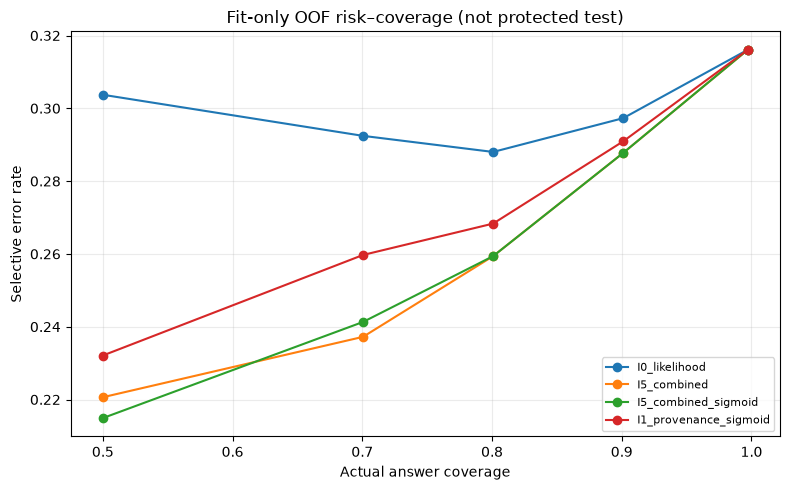

In [12]:
ALL_FIT_SCORES={**OOF,**CAL_OOF}
RISK_ROWS=[]
for k,score in ALL_FIT_SCORES.items():
    for target in RISK_COVERAGES:
        RISK_ROWS.append({'method':k,**selective_at(fit_y,score,fit_valid,target)})
RISK_TABLE=pd.DataFrame(RISK_ROWS)
RISK_TABLE.to_csv(OUTPUT_ROOT/'tables/I7_risk_coverage_fit.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
for k in ['I0_likelihood','I5_combined','I5_combined_sigmoid','I1_provenance_sigmoid']:
    if k in ALL_FIT_SCORES:
        d=RISK_TABLE[RISK_TABLE.method==k]
        ax.plot(d.realized_coverage,d.selective_risk,marker='o',label=k)
ax.set(xlabel='Actual answer coverage',ylabel='Selective error rate',title='Fit-only OOF risk–coverage (not protected test)')
ax.legend(fontsize=8);ax.grid(alpha=.25)
fig.tight_layout();fig.savefig(OUTPUT_ROOT/'plots/I7_risk_coverage_fit.png',dpi=170);plt.show()

## I8 — Component ablations and input provenance diagnostics

The ablation compares the same fit-only folds and the same executable-program gate. Feature groups may be correlated, and the observational data are too small to establish a causal effect. Outcomes should be described as *predictive association*. If the operation-question heuristic was not available, report that limitation, rather than treating structure proxies as semantic validation.

In [13]:
ABLATABLE=['I5_combined','I8_no_provenance','I8_no_relevance','I8_no_operations','I8_no_truncation']
ABLATABLE=[k for k in ABLATABLE if k in OOF]
ABLATION_TABLE=pd.DataFrame([basic_metrics(fit_y,OOF[k],fit_valid,k,'fit_oof') for k in ABLATABLE])
ABLATION_TABLE.to_csv(OUTPUT_ROOT/'tables/I8_feature_ablation.csv',index=False)
display(ABLATION_TABLE.sort_values('selective_risk_80'))

# Observable signals (not predictors using labels)
fit_merged=feat.iloc[fit_idx].copy()
fit_merged['_gold_for_audit_only']=fit_y
subrows=[]
for col in ['any_literal_unmatched','prompt_truncation_observed','has_division','has_table_operation']:
    for v,g in fit_merged.groupby(col,dropna=False):
        subrows.append({'subgroup_feature':col,'subgroup_value':str(v),'n':len(g),
                        'observed_execution_accuracy':float(g._gold_for_audit_only.mean())})
SUBGROUP=pd.DataFrame(subrows)
SUBGROUP.to_csv(OUTPUT_ROOT/'analysis/I1_I4_fit_subgroup_audit.csv',index=False)
display(SUBGROUP)

,method,source,n,n_valid,roc_auc,brier,aurc,selective_risk_80,coverage_80,accepted_80
0,I5_combined,fit_oof,698,696,0.668635,0.199893,0.217650,0.259392,0.80086,559
1,I8_no_provenance,fit_oof,698,696,0.667149,0.200069,0.220768,0.259392,0.80086,559
2,I8_no_relevance,fit_oof,698,696,0.641173,0.201290,0.237898,0.261181,0.80086,559
4,I8_no_truncation,fit_oof,698,696,0.668001,0.200874,0.214928,0.261181,0.80086,559
3,I8_no_operations,fit_oof,698,696,0.646860,0.203145,0.221302,0.271914,0.80086,559


,subgroup_feature,subgroup_value,n,observed_execution_accuracy
0,any_literal_unmatched,0,682,0.695015
1,any_literal_unmatched,1,16,0.125000
2,prompt_truncation_observed,0,333,0.717718
3,prompt_truncation_observed,1,365,0.649315
4,has_division,0,207,0.647343
5,has_division,1,491,0.696538
6,has_table_operation,0,677,0.675037
7,has_table_operation,1,21,0.904762


## I9 — Pre-declared fit-only decision, paired bootstrap, model freeze

The *primary* selection criterion is **lower fit-only OOF error at matched 80% coverage**, with AURC and Brier score as tie-breakers. We require a nontrivial fit-only improvement (at least **two percentage points** lower selective error) over B1 and a lower fit-only AURC before naming a verifier-aware improvement candidate. This criterion is a cautious engineering threshold, not a formal significance claim. The prior Phase-4B B4 fit OOF AURC is recorded as context; individual B4 fit scores are unavailable in the review ZIP, so a paired fit-only B4 comparison cannot be reconstructed here.

The prior Phase-4B `B1_raw` and `B4_grounding` policies remain **frozen historical baselines**. This follow-up's selected method is exploratory until independently confirmed on a protected test set.

In [14]:
# Rank only newly tested candidates using fit OOF, not prior inspected holdout.
ranking=CAL_TABLE.copy()
ranking=ranking[ranking.method!='I0_likelihood'].sort_values(
    ['selective_risk_80','aurc','brier'],ascending=True)
assert len(ranking)>0
best_name=str(ranking.iloc[0]['method'])
best_score=ALL_FIT_SCORES[best_name]
base_score=ALL_FIT_SCORES['I0_likelihood']
best_met=basic_metrics(fit_y,best_score,fit_valid,best_name,'fit_oof')
base_met=basic_metrics(fit_y,base_score,fit_valid,'I0_likelihood','fit_raw')
meets_practical_gate=(
    best_met['selective_risk_80'] <= base_met['selective_risk_80']-0.02
    and best_met['aurc']<base_met['aurc']
)

# Paired bootstrap in the fit only; equal selected count per resample.
rng=np.random.default_rng(RANDOM_SEED)
boot=[]
for _ in range(N_BOOT):
    idx=rng.integers(0,len(fit_y),size=len(fit_y))
    a=selective_at(fit_y[idx],base_score[idx],fit_valid[idx],TARGET_COVERAGE)['selective_risk']
    b=selective_at(fit_y[idx],best_score[idx],fit_valid[idx],TARGET_COVERAGE)['selective_risk']
    if a is not None and b is not None:boot.append(a-b) # positive favors new model
boot_ci=np.percentile(boot,[2.5,97.5]).tolist()

# Freeze candidate settings using calibration-fit data only.
selected_family=best_name.replace('_sigmoid','')
selected_features=GROUPS[selected_family]
selected_is_sigmoid=best_name.endswith('_sigmoid')
if selected_is_sigmoid:
    selected_model=fitted_sigmoid_calibrator(selected_features,C=1.0)
else:
    inner_c=select_inner_C(feat.iloc[fit_idx][selected_features].reset_index(drop=True),fit_y,fit_valid,RANDOM_SEED+700)
    selected_model=pipeline(inner_c)
selected_model.fit(feat.iloc[fit_idx][selected_features],fit_y)
model_path=OUTPUT_ROOT/'models/I9_fit_only_selected.joblib'
joblib.dump(selected_model,model_path)

# Operational thresholds are FROZEN from fit-only OOF scores, not derived on holdout.
# The 80% 'rank-matched' result is a research comparator; real deployment uses
# one fixed numerical threshold and may realize different coverage on fresh data.
def fit_only_threshold(score, valid, target_coverage=TARGET_COVERAGE):
    valid_scores=np.asarray(score,float)[np.asarray(valid,bool)]
    valid_scores=valid_scores[np.isfinite(valid_scores)]
    if not len(valid_scores): return float('inf')
    k=min(int(np.ceil(len(score)*target_coverage)),len(valid_scores))
    # kth-largest score; accept score >= threshold and valid programs only.
    return float(np.sort(valid_scores)[::-1][k-1])

fit_selected_threshold=fit_only_threshold(best_score,fit_valid)
fit_baseline_threshold=fit_only_threshold(base_score,fit_valid)

FIT_DECISION={
    'phase':'Phase-4B.1','mode':RUN_MODE,
    'selection_source':'698 calibration_fit examples only' if RUN_MODE=='full' else 'SMOKE subset (not research results)',
    'selected_candidate':best_name,
    'features':selected_features,
    'sigmoid_calibrated':selected_is_sigmoid,
    'primary_metric':'selective error at 80% target coverage; valid-program gate',
    'tie_breakers':['fit AURC','fit Brier'],
    'fit_raw_likelihood':base_met,'fit_selected':best_met,
    'fit_risk_difference_baseline_minus_candidate':float(base_met['selective_risk_80']-best_met['selective_risk_80']),
    'fit_bootstrap_ci_95_baseline_minus_candidate':boot_ci,
    'fixed_threshold_fitted_from_oof':fit_selected_threshold,
    'baseline_b1_threshold_fitted_from_fit':fit_baseline_threshold,
    'target_coverage':TARGET_COVERAGE,
    'threshold_note':'Fixed threshold derived from fit OOF; realized coverage may vary on new samples. No holdout threshold tuning.',
    'engineering_gate_2pp_and_lower_aurc':bool(meets_practical_gate),
    'new_superiority_claim_justified':False,
    'prior_B1_policy_remains_frozen':True,
    'historical_B4_fit_oof_aurc':float(b_oof_report.loc[b_oof_report.method=='B4_grounding','aurc'].iloc[0]),
    'method_checkpoint':str(model_path.resolve()),
    'checkpoint_sha256':digest_file(model_path),
    'protected_test_used':False,
    'holdout_used_for_selection':False,
    'question_operation_heuristic_status':question_semantic_status,
    'required_next_evidence':'One-time protected-test comparison after independent methodology freeze approval',
}
freeze_path=OUTPUT_ROOT/'manifests/phase4b1_fit_only_freeze.json'
write_json(freeze_path,FIT_DECISION)
write_json(OUTPUT_ROOT/'manifests/I9_fit_bootstrap.json',{
    'metric':'fit 80% selective risk B1 minus new candidate (positive favors candidate)',
    'n':len(fit_y),'n_bootstrap':len(boot),'ci_95':boot_ci})
print('FROZEN BEFORE SECONDARY HOLDOUT:',best_name,'| fit gate:',meets_practical_gate)
print('Fit risk@80 B1:',base_met['selective_risk_80'],'Candidate:',best_met['selective_risk_80'])
print('Fit paired bootstrap CI:',boot_ci)

FROZEN BEFORE SECONDARY HOLDOUT: I5_combined_sigmoid | fit gate: True
Fit risk@80 B1: 0.2880143112701252 Candidate: 0.259391771019678
Fit paired bootstrap CI: [0.007155635062611798, 0.05366726296958854]


## Secondary holdout diagnostic — *never used for method selection*

The historical 185-record FinQA calibration holdout has been inspected in prior Phase-4B/C research. We include a **single descriptive check after freezing** so existing B1/B4 results can be compared with the new candidate. It is not untouched external validation, may be optimistic after iterative research, and **must not trigger further feature or threshold tuning**. Any final proposed-method superiority claim belongs to the protected FinQA test.

In [15]:
secondary_report='NOT_RUN_SMOKE'
if SECONDARY_HOLDOUT_REPORT:
    # Fit-only freeze has already been saved above.
    assert freeze_path.exists()
    hold_feat=feat.iloc[hold_idx]
    hold_y=y_all[hold_idx]
    hold_valid=valid_all[hold_idx]
    ours=selected_model.predict_proba(hold_feat[selected_features])[:,1]
    hist=old_holdout_scores.pivot(index='record_id',columns='method',values='p_correct')
    hist=hist.reindex(hold_feat.record_id)
    assert hist.notna().all().all(), 'Missing historical holdout scores'
    comparative={
        'B1_prior':hist['B1_raw'].to_numpy(float),
        'B4_prior':hist['B4_grounding'].to_numpy(float),
        'I9_new_candidate':ours,
    }
    hold_rows=[]; hold_curve=[]
    for method,scores in comparative.items():
        hold_rows.append(basic_metrics(hold_y,scores,hold_valid,method,'previously_examined_holdout_descriptive'))
        for k in RISK_COVERAGES:hold_curve.append({'method':method,**selective_at(hold_y,scores,hold_valid,k)})
    HOLD_METRICS=pd.DataFrame(hold_rows)
    HOLD_CURVE=pd.DataFrame(hold_curve)
    HOLD_METRICS.to_csv(OUTPUT_ROOT/'tables/I9_secondary_holdout_comparison.csv',index=False)
    HOLD_CURVE.to_csv(OUTPUT_ROOT/'tables/I9_secondary_holdout_risk_coverage.csv',index=False)
    # Fixed operational thresholds, calibrated entirely on fit. This is different
    # from matched-count comparisons, which sort *this holdout* without labels.
    operational=[]
    fixed_thresholds={
        'B1_prior':FIT_DECISION['baseline_b1_threshold_fitted_from_fit'],
        'I9_new_candidate':FIT_DECISION['fixed_threshold_fitted_from_oof'],
    }
    for method,threshold in fixed_thresholds.items():
        pred=comparative[method]
        accepted=hold_valid & np.isfinite(pred) & (pred>=threshold)
        operational.append({
            'method':method, 'threshold_frozen_on_fit':float(threshold),
            'holdout_accepted':int(accepted.sum()),
            'holdout_realized_coverage':float(accepted.mean()),
            'holdout_selective_risk':float(np.mean(1-hold_y[accepted])) if accepted.any() else None,
            'interpretation':'descriptive; threshold was frozen before examining holdout scores',
        })
    pd.DataFrame(operational).to_csv(
        OUTPUT_ROOT/'tables/I9_secondary_fixed_threshold_policy.csv',index=False
    )
    out_hold=pd.DataFrame({'record_id':hold_feat.record_id.to_numpy(),
                           'fold':'calibration_holdout', 'execution_correct':hold_y,
                           'valid_program':hold_valid.astype(int)})
    for k,v in comparative.items():out_hold[k]=v
    out_hold.to_csv(OUTPUT_ROOT/'predictions/I9_secondary_holdout_scores.csv',index=False)
    print('Secondary holdout (previously examined; not a new test):')
    display(HOLD_METRICS)
    secondary_report='DESCRIPTIVE_ONLY_ALREADY_SEEN'

    # Descriptive paired bootstrap for new candidate versus frozen B1/B4.
    rng=np.random.default_rng(RANDOM_SEED+100)
    stats=[]
    for baseline in ['B1_prior','B4_prior']:
        raw_d=[]
        for _ in range(N_BOOT):
            ii=rng.integers(0,len(hold_y),size=len(hold_y))
            b=selective_at(hold_y[ii],comparative[baseline][ii],hold_valid[ii],TARGET_COVERAGE)['selective_risk']
            o=selective_at(hold_y[ii],ours[ii],hold_valid[ii],TARGET_COVERAGE)['selective_risk']
            if b is not None and o is not None: raw_d.append(b-o)
        stats.append({'baseline':baseline,'candidate':best_name,'n_bootstrap':len(raw_d),
                      'difference_baseline_minus_candidate':float(np.mean(raw_d)),
                      'ci_low':float(np.percentile(raw_d,2.5)),
                      'ci_high':float(np.percentile(raw_d,97.5)),
                      'interpretation':'descriptive, not independent confirmatory test'})
    pd.DataFrame(stats).to_csv(OUTPUT_ROOT/'tables/I9_secondary_paired_bootstrap.csv',index=False)

Secondary holdout (previously examined; not a new test):


,method,source,n,n_valid,roc_auc,brier,aurc,selective_risk_80,coverage_80,accepted_80
0,B1_prior,previously_examined_holdout_descriptive,185,184,0.545641,0.299643,0.284690,0.358108,0.8,148
1,B4_prior,previously_examined_holdout_descriptive,185,184,0.551026,0.222784,0.324385,0.324324,0.8,148
2,I9_new_candidate,previously_examined_holdout_descriptive,185,184,0.703846,0.208494,0.232520,0.283784,0.8,148


## Final integrity gates, Phase-4C interface, and reproducibility archive

- Machine-readable gates check alignment, non-leaking predictor whitelist, fit/holdout separation, pre-holdout candidate freeze and generated I1–I9 outputs.
- A **research outcome** of `NO_IMPROVEMENT` is allowed: the notebook will never convert a successful run into a false claim of methodological superiority.
- Final results for paper submission still require a pre-specified protected-test evaluation and separately validated FinTrust dimension scoring protocols.

In [16]:
required=[
    'manifests/source_fingerprints.json','manifests/feature_contract.json',
    'tables/I5_I8_fit_oof_comparison.csv','tables/I6_calibration_comparison.csv',
    'tables/I7_risk_coverage_fit.csv','tables/I8_feature_ablation.csv',
    'analysis/I1_I4_fit_subgroup_audit.csv','predictions/I5_fit_oof_scores.csv',
    'models/I9_fit_only_selected.joblib','manifests/phase4b1_fit_only_freeze.json',
    'manifests/I9_fit_bootstrap.json'
]
assert all((OUTPUT_ROOT/p).is_file() for p in required)
assert not any(any(t in f.lower() for t in FORBIDDEN_TOKENS) for fs in GROUPS.values() for f in fs)
assert input_manifest['protected_tests_used'] is False
assert len(set(fit_idx)&set(hold_idx))==0
assert FIT_DECISION['holdout_used_for_selection'] is False
assert FIT_DECISION['checkpoint_sha256']==digest_file(model_path)

readiness={
    'phase':'4B.1','run_mode':RUN_MODE,'status':'PASS_RESEARCH_AUDIT' if RUN_MODE=='full' else 'PASS_SMOKE_ONLY',
    'all_I1_to_I9_implemented':True,'n_fit_used':len(fit_idx),'n_reserved_holdout':len(hold_idx),
    'selected_candidate':best_name,'selected_before_holdout':True,
    'fit_only_practical_improvement_gate':bool(meets_practical_gate),
    'research_conclusion':'CANDIDATE_FOR_PROTECTED_TEST' if meets_practical_gate else 'NO_ESTABLISHED_FIT_IMPROVEMENT',
    'secondary_holdout_status':secondary_report,
    'validation_holdout_already_seen_in_prior_phases':True,
    'question_operation_semantics_status':question_semantic_status,
    'full_semantic_financial_grounding_verified':False,
    'risk_estimator_runnable':True,
    'protected_test_evaluated':False,
    'fintrust_7_dimension_protocol_status':'PENDING_SEPARATE_EVALUATOR_VALIDATION',
    'notebook_pass_does_not_equal_publication_success':True,
    'source_hashes':{'phase4a':input_manifest['phase4a_sha256'],'phase4b':input_manifest['phase4b_sha256']},
}
write_json(OUTPUT_ROOT/'manifests/phase4b1_readiness.json',readiness)
write_json(OUTPUT_ROOT/'manifests/phase4c_candidate_handoff.json',{
    'schema':'trustfin.phase4b1.v1','source_freeze':'manifests/phase4b1_fit_only_freeze.json',
    'candidate':best_name,'model':'models/I9_fit_only_selected.joblib',
    'selected_features':selected_features,
    'comparison_baselines':['Phase4B B1_raw','Phase4B B4_grounding'],
    'selection_partition':'calibration_fit_only',
    'secondary_holdout':'previously_seen_descriptive_not_confirmatory',
    'required_external_confirmation':'FinQA protected test after final independent freeze review',
    'no_protected_tests_loaded':True,
})

# Archive only project-generated outputs. No original dataset or model weights copied.
zip_out=OUTPUT_ROOT/'Phase4B_1_Review_Package.zip'
with zipfile.ZipFile(zip_out,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUTPUT_ROOT.rglob('*')):
        if p.is_file() and p!=zip_out:
            z.write(p,arcname=p.relative_to(OUTPUT_ROOT))
print('PHASE-4B.1 STATUS:',readiness['status'])
print('RESEARCH OUTCOME:',readiness['research_conclusion'])
print('Package:',zip_out)

PHASE-4B.1 STATUS: PASS_RESEARCH_AUDIT
RESEARCH OUTCOME: CANDIDATE_FOR_PROTECTED_TEST
Package: /home/heet18/Downloads/Research Papers/artifacts/phase4b_1/Phase4B_1_Review_Package.zip


## End of notebook — what students should share

1. The **executed notebook** with all output cells (full mode).
2. **`Phase4B_1_Review_Package.zip`**, which includes fit-only model comparisons, ablations, calibration, risk–coverage curves, bootstrap uncertainty, source fingerprints, selected checkpoint, and secondary descriptive holdout tables.
3. If available, the original Phase-2.1 **validation JSONL path** and E5 model commit (not protected-test examples), so that question–operation heuristics can be audited.

### Criteria before moving to the protected test

- All integrity gates pass and the candidate is frozen **without using the previously examined holdout**.
- The model's fit-only risk-ranking benefit over B1 is positive and stable, ideally with a paired confidence interval excluding zero.
- B1/B4 must remain as comparisons on the exact same evaluation set and coverage.
- If the improved model fails, report a **negative or inconclusive** result and avoid claiming that verifier-aware selective prediction is superior.
- Keep protected FinQA test, FiQA test, FOMC, and FinTrust untouched until final methodology and evaluator protocols have been approved.

**Paper claim permitted now:** We developed and evaluated a lightweight validation-only verifier-aware candidate. **Not yet permitted:** The new candidate is proven to reduce financial errors on unseen protected tests.